# Local action consistency

LAC@8 of a key (offline, held-out demos) vs the closed-loop success of a lookup with it: one point per backbone key, before and after fine-tuning.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

import utils as u

FS_SMALL = 9  # pt: \small of the paper
PAGE_WIDTH = 5.5  # in: \textwidth of the paper (\linewidth of a figure)
ROOT = Path.cwd().parent
data_path = ROOT / "results"
figs_path = ROOT / "analysis/figs"
style_path = ROOT / "analysis/figure.mplstyle"

In [2]:
data = json.loads((data_path / "data.json").read_text())
figs_path.mkdir(exist_ok=True)
plt.style.use(style_path)

In [3]:
GROUPS = {  # legend section -> colour role of a key -> (label, colour)
    "Image encoder": {"resnet": ("ResNet-18", u.Colour.HUMAN_DARK), "dinov2": ("DINOv2", u.Colour.HUMAN),
                      "learnt": ("$k$-NN (LAC key)", u.Colour.KNN)},
    "VLM": {"before": ("Before fine-tuning", u.Colour.BEFORE), "after": ("After fine-tuning", u.Colour.AFTER)},
}  # fmt: skip

In [4]:
pts = data["neighbor_metric"]["correlation"]["points"]  # one key per backbone
pi0 = pts["π0 LIBERO L12"]  # LAC far below the others (a broken key): noted instead of plotted
on = {n: v for n, v in pts.items() if n != "π0 LIBERO L12"}
role = {n: "learnt" if "learnt" in n else "resnet" if n == "ResNet-18 grid" else "dinov2" if n == "DINOv2-S" else
        "after" if " LIBERO " in n else "before" for n in on}  # fmt: skip
fair = np.array([(v["lac@8"], v["success"]) for v in on.values() if v["fair"]])  # keys that never saw these demos
fit = np.polyfit(*fair.T, 1)
gx = np.array([fair[:, 0].min() - 0.01, fair[:, 0].max() + 0.01])

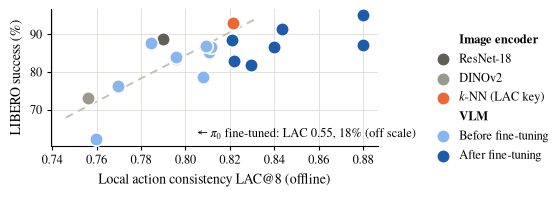

In [5]:
fig, ax = plt.subplots(figsize=(PAGE_WIDTH, 1.872), layout="constrained")
ax.plot(gx, np.polyval(fit, gx), color=u.Colour.AXIS, linestyle=(0, (4, 3)), linewidth=1.4, zorder=1)
handles = []
for title, roles in GROUPS.items():
    handles.append(Line2D([], [], linestyle="", label=title))  # section title: an entry without a marker
    for r, (label, colour) in roles.items():
        sel = [v for n, v in on.items() if role[n] == r]
        handles.append(ax.scatter([v["lac@8"] for v in sel], [v["success"] for v in sel], s=95, color=colour,
                                  edgecolor="white", linewidth=1.2, zorder=3, label=label))  # fmt: skip
legend = fig.legend(handles=handles, loc="outside right center", frameon=False, handletextpad=0.3)
for text in legend.get_texts():
    text.set_fontweight("bold" if text.get_text() in GROUPS else "normal")
ax.annotate(f"← $\\pi_0$ fine-tuned: LAC {pi0['lac@8']:.2f}, {pi0['success']:.0f}% (off scale)", xy=(0.45, 0.06),
            xycoords="axes fraction", fontsize=FS_SMALL)  # fmt: skip
ax.set_xlabel("Local action consistency LAC@8 (offline)")
ax.set_ylabel("LIBERO success (%)")
ax.grid(True)
ax.set_axisbelow(True)
fig.savefig(figs_path / "neighbors.pdf")